# Figure 7 — Accuracy vs network size

Pena, Vellmer, Bernardi, Roque & Lindner (2018), Front. Comput. Neurosci. 12:9, doi:10.3389/fncom.2018.00009. Scheme after Dummer, Wieland & Lindner (2014).

**Caption (paper):** Performance of the scheme improves with network size; gE = 4.2, gI = 4.0 (Figure 6A). (A) Relative error (Eq. 19) vs N_E. (B) Fano factor (scheme dotted, network solid). (C) Correlation time τc. Text: N_E ≥ 20,000 needed for < 1 % error.

**Method here:** fixed C_E = 1000, C_I = 250 while N_E grows; the scheme does not depend on N_E (reuses Figure 6A).

**Shared implementation choices** (all figures, see `pena_scheme.py`, `pena_network.py`):
- Euler, `dt = 0.1 ms`; voltage clamped at reset during the refractory period (scheme and network).
- Spectra: Eq. 5, two-sided, 2 s windows after a 1 s transient (Δf = 0.5 Hz).
  Fano factor = mean of S at 0.5 and 1 Hz divided by ν; τc from Eq. 7 with the estimator variance subtracted.
- Scheme generation 0: white noise at the diffusion-approximation (mean-field) rate; the paper does not
  specify its starting point. Inhibition-dominated cases (g > 4) use the all-past rate average (Eq. 11).
- Networks are simulated at reduced size (default N_E = 10,000 instead of 100,000) to fit 2 CPUs / ~2 GB;
  partners are drawn with replacement. Larger sizes are available via the config cell but need far more memory.

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()
if not (HERE / "pena2018_params.py").exists():
    HERE = HERE / "05_Pena2018_Replication"
sys.path.insert(0, str(HERE))

from pena2018_params import params_for
import pena_scheme as ps
import pena_runs as pr
FIGURES = HERE / "figures"; FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
P = params_for(7) | {"reported_rates_Hz": None}
P6 = params_for(6)
gE, gI = P["gE"], P["gI"]
N_E_VALUES = [2_500, 5_000, 10_000, 20_000]   # paper reaches 100,000
N_WINDOWS = 10

In [3]:
scheme = pr.two_pop(gE, gI, P6)
nets = {}
for NE in N_E_VALUES:
    print(f"--- N_E = {NE}")
    nets[NE] = pr.two_pop(gE, gI, P6, N_E=NE, n_windows=N_WINDOWS)

loaded scheme_twopop_gE4.2_gI4.0_1a23196028.npz
--- N_E = 2500
loaded net_twopop_a5603c7608.npz
--- N_E = 5000
loaded net_twopop_7325770141.npz
--- N_E = 10000
loaded net_twopop_cf873cdee6.npz
--- N_E = 20000
loaded net_twopop_0b08cd087e.npz


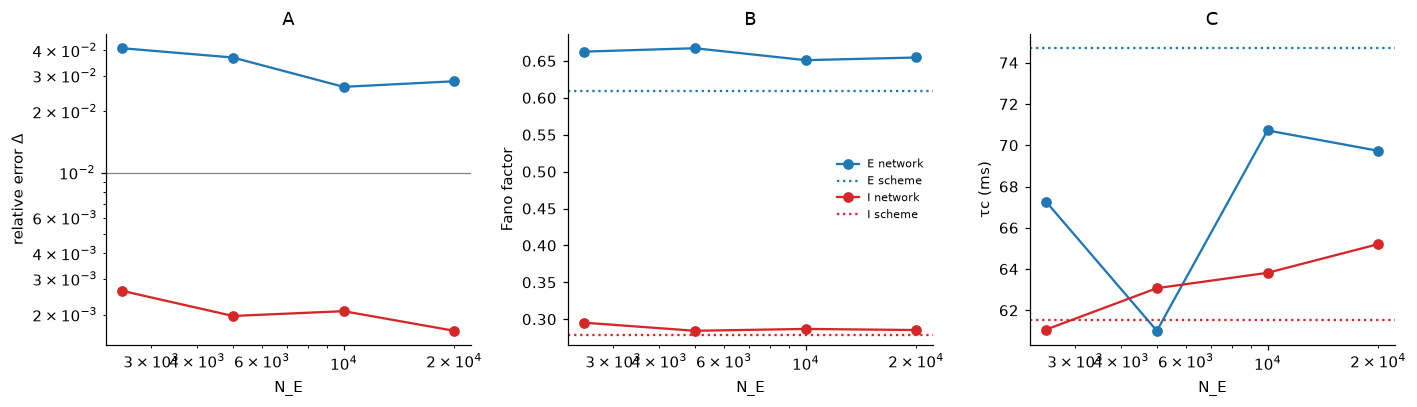

saved figure07_network_size.csv (28 data points)
N_E=  2500: err E 0.0409, I 0.0026; rates 3.13, 9.87 Hz
N_E=  5000: err E 0.0368, I 0.0020; rates 3.17, 9.80 Hz
N_E= 10000: err E 0.0264, I 0.0021; rates 3.20, 9.77 Hz
N_E= 20000: err E 0.0282, I 0.0017; rates 3.24, 9.77 Hz


In [4]:
f = scheme["f"]
err = {pop: [ps.relative_error(f, nets[NE][f"S_{pop}"], scheme["S_final"][a], 2 * float(nets[NE]["nu_I"]))
             for NE in N_E_VALUES] for a, pop in enumerate("EI")}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (pop, c) in enumerate([("E", "tab:blue"), ("I", "tab:red")]):
    axes[0].loglog(N_E_VALUES, err[pop], "o-", color=c, label=pop)
    axes[1].semilogx(N_E_VALUES, [float(nets[NE][f"FF_{pop}"]) for NE in N_E_VALUES], "o-", color=c, label=f"{pop} network")
    axes[1].axhline(scheme["FF"][a], ls=":", color=c, label=f"{pop} scheme")
    axes[2].semilogx(N_E_VALUES, [1e3 * float(nets[NE][f"tau_c_{pop}"]) for NE in N_E_VALUES], "o-", color=c)
    axes[2].axhline(1e3 * scheme["tau_c"][a], ls=":", color=c)
axes[0].axhline(0.01, color="gray", lw=0.8)
axes[0].set(xlabel="N_E", ylabel="relative error Δ", title="A")
axes[1].set(xlabel="N_E", ylabel="Fano factor", title="B"); axes[1].legend(frameon=False, fontsize=7)
axes[2].set(xlabel="N_E", ylabel="τc (ms)", title="C")
fig.tight_layout(); fig.savefig(FIGURES / "figure07_network_size.png", dpi=200); plt.show()
import pena_export; pena_export.figure_csv(fig, FIGURES / "figure07_network_size.csv")
for i, NE in enumerate(N_E_VALUES):
    print(f"N_E={NE:6d}: err E {err['E'][i]:.4f}, I {err['I'][i]:.4f}; rates {float(nets[NE]['nu_E']):.2f}, {float(nets[NE]['nu_I']):.2f} Hz")

## Notes

_Filled in after the run._